# Skill suggestion: the right skill, or none at all

<a href="https://colab.research.google.com/github/sixhobbits/colab-demo/blob/main/cookbooks/skill_suggestion/skill_suggestion.ipynb" target="_blank"><img src="https://img.shields.io/badge/Open%20in%20Colab-F9AB00?style=for-the-badge&logo=googlecolab&logoColor=white" alt="Open in Colab" height="28"></a> <a href="https://github.com/sixhobbits/colab-demo/blob/main/cookbooks/skill_suggestion/skill_suggestion.ipynb" target="_blank"><img src="https://img.shields.io/badge/View%20on%20GitHub-24292F?style=for-the-badge&logo=github&logoColor=white" alt="View on GitHub" height="28"></a>

> **No API key needed.** The code downloads this cookbook's saved answers, so
> *Run all* replays every TypeSafe call from them. It needs no TypeSafe account
> and costs nothing. To call the API yourself, set `TYPESAFE_API_KEY` and
> `DOWNLOAD_CACHE = False`.

From [the docs page](https://console.typesafe.ai/docs/cookbooks/skill_suggestion).

*Agents choose skills from an index that puts every skill, with its description truncated,
into the system message. This degrades skill selection and induces context rot for the rest
of the session. We add two TypeSafe requests per turn, one to rank skills and one to verify
the choice. They cut wrong skill loads by half and needless ones by nearly two thirds.*

An agent with a large skill roster makes its choice on almost no information. The roster
reaches it as an index: one line per skill, with the description truncated so the full text
doesn't crowd out the conversation. Hermes, the agent harness used here, cuts it to 60
characters by default. At that width, the Office skill that *edits* `.pptx` files and the
finance skill that *builds* decks both read as PowerPoint tools. Ask for changes to an
existing deck and the agent may load the one that builds new ones. On a turn where no skill
fits at all, it may still load one anyway, because a list of names invites a guess.

We use progressive disclosure, reading all 194 skills cheaply and then reading three of
them in detail. Two TypeSafe requests go in front of the decision on which skill to load,
if any. The first ranks every skill in the roster against the user's turn and answers
whether the turn needs a skill at all. The second re-reads only the top three, now with
each skill's full description and the opening of its instructions, and is free to reject
all of them.

The winner's name goes into one extra line of the agent's system prompt for that turn:

```
<skill_relevance>
Relevant to the current request: pptx-author. Ignore this if it does not fit what the user
actually asked for.
</skill_relevance>
```

The agent keeps its full index and its own judgement, and that one line only tells it which
entry to look at first. Over 452 requests against `claude-haiku-4-5-20251001`, using skills
from the Hermes roster:

| | loads the wrong skill | loads one when nothing fits |
|---|---|---|
| agent alone, with just its roster | 15.7% | 14.0% |
| **agent with a Jev suggestion** | **7.9%** | **5.2%** |
| agent handed the right answer | 3.2% | 4.1% |

The third row is the floor: an agent handed the right skill still does not always load it,
and no selection method gets below that.

You end up with a `suggest()` function that returns at most one skill name, a
`suggestion_block()` that wraps it for the system prompt, and the harness that produced the
table above, ready to point at your own roster.

<img src="https://raw.githubusercontent.com/sixhobbits/colab-demo/main/cookbooks/skill_suggestion/skill_suggestion-diagram-562dd74f3c.png" alt="Diagram" width="1176">

## Setup

- Install the TypeSafe client, the Anthropic client, and the shared cookbook helpers.
- Set a [TypeSafe API key](https://console.typesafe.ai/keys), and an Anthropic key for the
  agent being measured.

```bash
pip install anthropic matplotlib ipython 'cooksafe>=0.3.0,<0.4.0'
export TYPESAFE_API_KEY=your-key-here
export ANTHROPIC_API_KEY=your-key-here
```

> **Note:** this page's code blocks form one script. To run it, put them in one file in
> the order they appear.

## Caching results

We cache each call's result in `skill_suggestion_cache.json`, keyed on its inputs, and the
code downloads the published one, so a run replays the numbers below instead of calling
either API. The published run used
`jev-1.14.0` and `claude-haiku-4-5-20251001`, rendered 2026-10-30.

In [ ]:
%pip install -q 'anthropic' 'matplotlib' 'typesafe-sdk>=0.7.0' 'ipython' 'cooksafe>=0.3.0,<0.4.0'

In [ ]:
import json
import os
import urllib.request
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from time import perf_counter

import anthropic
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, PercentFormatter
from cooksafe import JsonCache, make_playground_link
from IPython.display import Markdown, display
from typesafe_sdk import Choice, Noul, TypeSafeClient

matplotlib.use("Agg")  # headless render

TYPESAFE_MODEL = "jev-1.14.0"  # the page's model; "jev-latest" runs the newest, live
AGENT_MODEL = (
    "claude-haiku-4-5-20251001"  # the agent under test, pinned so scores are stable
)

SHORTLIST = 3  # candidates carried from the first request into the second
EXCERPT_CHARS = (
    700  # SKILL.md characters each candidate brings; the roster file stores 1600
)
ACTION_THRESHOLD = (
    0.30  # mean of the three action nouls; at or above it, a skill is wanted
)
NAMED_THRESHOLD = (
    0.50  # the "names a method" noul; at or above it, a skill is wanted too
)
FITS_THRESHOLD = (
    0.30  # a shortlist whose best "does this fit" noul is under this is dropped
)
WORKERS = 8  # small pool: enough to keep a live run to minutes, gentle on rate limits

assert EXCERPT_CHARS <= 1600, (
    "the shipped roster file stores 1600 body characters per skill"
)

client = TypeSafeClient(
    api_key=os.environ.get(
        "TYPESAFE_API_KEY", "cache-only"
    ),  # keyless kernels replay the cache
    base_url=os.environ.get("TYPESAFE_ENDPOINT"),
    timeout=120.0,
)
agent = anthropic.Anthropic(api_key=os.environ.get("ANTHROPIC_API_KEY", "cache-only"))


EXAMPLES = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/skill_suggestion"
)


def download(name: str) -> Path:
    """Fetch one of this cookbook's files from typesafe-public-examples unless it is on disk."""
    path = Path(name)
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{EXAMPLES}/{name}", path)
    return path


CACHE = Path("skill_suggestion_cache.json")
# True fills CACHE with the published answers, so the run makes no requests. To run
# live, set it to False and delete CACHE; a CACHE already on disk is never overwritten.
DOWNLOAD_CACHE = True
if DOWNLOAD_CACHE:
    download(CACHE.name)
json_cache = JsonCache(CACHE)

## Step 1: load the roster

`hermes_roster.json` holds the 194 skills of
[NousResearch/hermes-agent](https://github.com/NousResearch/hermes-agent) at one pinned
commit. Each record holds a skill's name and category, the description as the index shows
it, the full description, and the opening of its `SKILL.md`. The skills' licences are in
[`DATA_LICENSE.md`](https://github.com/typesafe-ai/typesafe-public-examples/blob/main/cookbooks/skill_suggestion/DATA_LICENSE.md).

The index below, and the instructions above it in the prompt, are copied from Hermes.

In [ ]:
ROSTER = json.loads(download("hermes_roster.json").read_text(encoding="utf-8"))
BY_NAME = {skill["name"]: skill for skill in ROSTER}

# Verbatim from hermes-agent agent/prompt_builder.py:_render_skills_index.
PREAMBLE = (
    "## Skills\n"
    "Before replying, scan the skills below. If a skill matches or is even partially relevant to your "
    "task, you MUST load it with skill_view(name) and follow its instructions. Err on the side of "
    "loading — it is always better to have context you don't need than to miss critical steps, pitfalls, "
    "or established workflows. Skills contain specialized knowledge — API endpoints, tool-specific "
    "commands, and proven workflows that outperform general-purpose approaches. Load the skill "
    "even if you think you could handle the task with basic tools like web_search or terminal. "
    "Skills also encode the user's preferred approach, conventions, and quality standards for tasks like "
    "code review, planning, and testing — load them even for tasks you already know how to do, because "
    "the skill defines how it should be done here.\n"
    "If a skill has issues, fix it with skill_manage(action='patch').\n"
    "After difficult/iterative tasks, offer to save as a skill. If a skill you loaded was missing steps, "
    "had wrong commands, or needed pitfalls you discovered, update it before finishing.\n"
    "\n"
)
FOOTER = "\n\nOnly proceed without loading a skill if genuinely none are relevant to the task."
IDENTITY = (
    "You are Hermes, a capable AI assistant with access to tools and a library "
    "of skills. You help the user with coding, research, and everyday tasks.\n\n"
)


def render_index() -> str:
    """The body of <available_skills>: skills grouped by category, both sorted by name."""
    by_category = defaultdict(list)
    for skill in ROSTER:
        by_category[skill["category"]].append(skill)
    lines = []
    for category in sorted(by_category):
        skills = sorted(by_category[category], key=lambda s: s["name"])
        if len(skills) == 1:  # a one-skill category is a single top-level row
            lines.append(f"  - {skills[0]['name']}: {skills[0]['description']}")
            continue
        lines.append(f"  {category}:")
        lines.extend(f"    - {skill['name']}: {skill['description']}" for skill in skills)
    return "\n".join(lines)


CATALOG_PROMPT = (
    IDENTITY
    + PREAMBLE
    + "<available_skills>\n"
    + render_index()
    + "\n</available_skills>"
    + FOOTER
)

widths = [len(skill["description"]) for skill in ROSTER]
print(f"{len(ROSTER)} skills in {len({s['category'] for s in ROSTER})} categories")
print(f"roster prompt: {len(CATALOG_PROMPT):,} characters")
print(
    f"index description: {sum(widths) / len(widths):.0f} characters on average, "
    f"{max(widths)} at most"
)
print("\none category, as the agent reads it:")
index_lines = render_index().splitlines()
start = index_lines.index("  apple:")
end = next(
    i
    for i in range(start + 1, len(index_lines))
    if not index_lines[i].startswith("    ")
)
print("\n".join(index_lines[start:end]))

194 skills in 32 categories
roster prompt: 16,376 characters
index description: 55 characters on average, 60 at most

one category, as the agent reads it:
  apple:
    - apple-notes: Manage Apple Notes via memo CLI: create, search, edit.
    - apple-reminders: Apple Reminders via remindctl: add, list, complete.
    - findmy: Track Apple devices/AirTags via FindMy.app on macOS.
    - imessage: Send and receive iMessages/SMS via the imsg CLI on macOS.


## Step 2: score the agent on its own

`requests.json` holds 452 single-turn requests, 280 of them covered by exactly one skill
and the other 172 covered by nothing.

The covered requests were written by Claude Sonnet 5 from each skill's own `SKILL.md`, so
the labels are trustworthy and the requests are easier than the ones users send.

The 172 uncovered ones were all written to punish guessing: 84 everyday requests, 42
technical questions no skill serves (*explain what a monad is*), and 46 that ask for
something specific the roster has no skill for, like *post this to Mastodon* on a roster
that covers X and nothing else.

Scoring reads the agent's first response only. Both numbers are error rates, so lower is
better on each:

- **wrong load**: of the covered requests, the share where the first `skill_view` call was
  not the covering skill. A turn that loaded nothing at all counts as a miss.
- **needless load**: of the uncovered requests, the share where the agent called
  `skill_view` at all.

In [ ]:
REQUESTS = json.loads(download("requests.json").read_text(encoding="utf-8"))
POSITIVES = [p for p in REQUESTS if p["gold"]]
NEGATIVES = [p for p in REQUESTS if not p["gold"]]

print(
    f"{len(REQUESTS)} requests: {len(POSITIVES)} covered by a skill "
    f"({len({p['gold'] for p in POSITIVES})} distinct skills), {len(NEGATIVES)} covered by none"
)
print(f"\ncovered   [{POSITIVES[0]['gold']}]  {POSITIVES[0]['text']}")
print(f"uncovered  {NEGATIVES[0]['text']}")

452 requests: 280 covered by a skill (145 distinct skills), 172 covered by none

covered   [1password]  I've got a config.yaml with `{{ op://app-prod/db/password }}` placeholders in it — can you set up my project to pull the real values in at runtime instead of hardcoding them?
uncovered  Add these three cards to our Trello backlog.


The suggestion goes in its own block of the system prompt, after the roster rather than
inside it, so the roster text is identical on every turn to maintain prefix caching.

The agent has a minimal set of tools, including `skill_view` to load a skill using a
free-text name. The name must match the skill exactly for a correct load.

In [ ]:
# Verbatim from hermes-agent tools/skills_tool.py:SKILL_VIEW_SCHEMA.
SKILL_VIEW_DESCRIPTION = (
    "Load a skill's SKILL.md, or one of its linked references, templates or scripts. "
    "The first call returns SKILL.md plus a 'linked_files' dict; call again with "
    "file_path to read one."
)
TOOLS = [
    {
        "name": "skill_view",
        "description": SKILL_VIEW_DESCRIPTION,
        "input_schema": {
            "type": "object",
            "properties": {
                "name": {"type": "string", "description": "The skill name."}
            },
            "required": ["name"],
        },
    },
    {
        "name": "terminal",
        "description": "Run a shell command on the user's machine and return its output.",
        "input_schema": {
            "type": "object",
            "properties": {"command": {"type": "string"}},
            "required": ["command"],
        },
    },
    {
        "name": "read_file",
        "description": "Read a file from the user's filesystem.",
        "input_schema": {
            "type": "object",
            "properties": {"path": {"type": "string"}},
            "required": ["path"],
        },
    },
    {
        "name": "web_search",
        "description": "Search the web and return result snippets.",
        "input_schema": {
            "type": "object",
            "properties": {"query": {"type": "string"}},
            "required": ["query"],
        },
    },
]


@json_cache
def run_turn(
    arm: str, roster: str, tools_json: str, request: str, suggestion: str, agent_model: str
) -> dict:
    """One measured turn. ``arm`` is in the key so each arm samples independently."""
    system = [{"type": "text", "text": roster, "cache_control": {"type": "ephemeral"}}]
    if suggestion:
        system.append({"type": "text", "text": suggestion})  # after the breakpoint
    response = agent.messages.create(
        model=agent_model,
        max_tokens=1024,
        system=system,
        tools=json.loads(tools_json),
        messages=[{"role": "user", "content": request}],
    )
    return {
        "loaded": [
            str(block.input.get("name", ""))
            for block in response.content
            if block.type == "tool_use" and block.name == "skill_view"
        ],
    }


def summarise(turns: dict[str, dict]) -> dict[str, float]:
    """Two failure rates: wrong loads on covered requests, needless ones on uncovered."""
    hits = [turns[p["text"]]["loaded"][:1] == [p["gold"]] for p in POSITIVES]
    over = [bool(turns[p["text"]]["loaded"]) for p in NEGATIVES]
    return {
        # both metrics are errors, so the two columns read the same direction
        "wrong_load": 1 - sum(hits) / len(hits),
        "needless_load": sum(over) / len(over),
    }


def run_arm(arm: str, suggestions: dict[str, str]) -> dict[str, dict]:
    """One measured turn per request, in a small pool. 452 calls."""
    texts = [request["text"] for request in REQUESTS]
    with ThreadPoolExecutor(max_workers=WORKERS) as pool:
        turns = pool.map(
            lambda t: run_turn(
                arm,
                CATALOG_PROMPT,
                json.dumps(TOOLS),
                t,
                suggestions.get(t, ""),
                agent_model=AGENT_MODEL,
            ),
            texts,
        )
        return dict(zip(texts, turns))

The agent runs first with nothing but its roster, the way it works today. Its two error
rates are the baseline.

In [ ]:
baseline = run_arm("baseline", {})
base_scores = summarise(baseline)
print(
    f"wrong loads    {base_scores['wrong_load']:.1%}   ({len(POSITIVES)} covered requests)"
)
print(
    f"needless loads {base_scores['needless_load']:.1%}   ({len(NEGATIVES)} uncovered requests)"
)

# where the wrong loads land: a neighbour of the right skill, or somewhere unrelated?
misses = [
    (p["gold"], baseline[p["text"]]["loaded"][0])
    for p in POSITIVES
    if baseline[p["text"]]["loaded"] and baseline[p["text"]]["loaded"][0] != p["gold"]
]
same_category = sum(
    1
    for gold, got in misses
    if got in BY_NAME and BY_NAME[got]["category"] == BY_NAME[gold]["category"]
)
print(
    f"\nof {len(misses)} wrong first picks, {same_category} came from the right skill's own "
    f"category"
)

wrong loads    15.7%   (280 covered requests)
needless loads 14.0%   (172 uncovered requests)

of 26 wrong first picks, 11 came from the right skill's own category


Wrong loads land in the right skill's own category far more often than chance would put
them there, so the hard part is telling a few lookalikes apart. The agent is already
looking in roughly the right place.

## Step 3: rank the whole roster

One request carries two kinds of question:

- **`which`** is a [`Choice`](https://console.typesafe.ai/docs/primitives/choice) question
  over all 194 skill names, with the index description as each option's criteria (the same
  text the agent itself gets). Its probabilities are the ranking.
- **three [`Noul`](https://console.typesafe.ai/docs/primitives/noul) questions about the
  request**, each asking in a different way whether the request wants an action taken
  rather than an explanation given. We average the three, flipping `prose_suffices`
  because a yes there means no skill is needed.
- **one `Noul` question, `named`**: does the request ask for a specific named tool,
  format, template, or method?

Both kinds go out in one request, so the ranking and the check cost one round trip.

Write the three action questions to ask whether an action is wanted. A question about
subject matter will not separate *explain what a monad is* from a request that needs a
skill, since both are software.

A turn can need a skill for either of two reasons: it wants an action taken, or it names a
method a skill owns, such as a meme template or a Suno prompt. The three action questions
measure the first reason, so we average them. `named` measures the second, so it gets its
own threshold instead of joining the average, where the three action answers would
outvote it. We suggest nothing only when both reasons come back low.

One `Choice` question holds a roster this size comfortably. A few times larger, you would
split it into chunks, rank each chunk, and then rerank the chunk winners as in step 4.

In [ ]:
CHOICE_INSTRUCTIONS = (
    "Which of these skills, if any, is the right one to load to help with the "
    "user's latest request?"
)
ACTION_QUESTIONS = {
    "acts_on_user_system": (
        "Is the assistant being asked to act on the user's files, accounts, devices, "
        "or online services, rather than only to explain or advise?"
    ),
    "would_follow_documented_procedure": (
        "Would a careful expert answering this consult a specific documented procedure "
        "or set of commands, rather than answering from general understanding?"
    ),
    "prose_suffices": (
        "Could a knowledgeable generalist fully satisfy this request in prose, with "
        "no tools, no documentation, and no access to the user's files or accounts?"
    ),
}
INVERTED = {"prose_suffices"}  # a yes here points away from needing a skill
NAMED_QUESTION = (
    "Does the request ask for a specific named tool, format, template, or method to be "
    "used, rather than for general help?"
)


def build_state(request: str) -> dict:
    return {"request": request, "recent_context": ""}


def as_json(questions: dict) -> str:
    return json.dumps(
        {key: q.model_dump(mode="json", exclude_none=True) for key, q in questions.items()}
    )


def wide_questions() -> dict:
    questions = {
        "which": Choice(
            instructions=CHOICE_INSTRUCTIONS,
            criteria={skill["name"]: skill["description"] for skill in ROSTER},
        )
    }
    for key, text in ACTION_QUESTIONS.items():
        questions[f"gate::{key}"] = Noul(instructions=text)
    questions["named"] = Noul(instructions=NAMED_QUESTION)
    return questions


@json_cache
def rank_wide(request: str, questions_json: str, model: str) -> dict:
    """Request 1: rank all 194 skills, and score the request for whether a skill applies."""
    started = perf_counter()
    response = client.system_one(
        state=build_state(request),
        questions=json.loads(questions_json),
        model=model,
    )
    ranked = sorted(
        response.answers["which"].probabilities.items(), key=lambda kv: -kv[1]
    )
    values = {
        key.removeprefix("gate::"): answer.noul
        for key, answer in response.answers.items()
        if key.startswith("gate::")
    }
    return {
        "ranked": ranked[
            :12
        ],  # more than any shortlist needs, and keeps the cache small
        "values": values,
        "named": response.answers["named"].noul,
        "seconds": round(perf_counter() - started, 2),
    }


def first_pass(request: str) -> dict:
    """Request 1, plus the three action answers averaged into ``action``."""
    wide = rank_wide(request, as_json(wide_questions()), model=TYPESAFE_MODEL)
    oriented = [(1.0 - v) if k in INVERTED else v for k, v in wide["values"].items()]
    return {**wide, "action": sum(oriented) / len(oriented)}


def needs_skill(wide: dict) -> bool:
    """Either reason is enough: an action is wanted, or a named method is asked for."""
    return wide["action"] >= ACTION_THRESHOLD or wide["named"] >= NAMED_THRESHOLD


DEMO = [
    "Can you save this recipe as a new note in my 'Recipes' folder in Notes.app so it syncs"
    " to my phone? Just write it up in whatever editor pops up.",
    "I've got a client pitch deck as a .pptx template - I need to duplicate slide 4's layout"
    " for three new product slides and then strip out any unused media/rels afterward so the"
    " file isn't bloated.",
    "Post this announcement to my Mastodon account.",
    "Can you make me a Gru's Plan meme about a developer's plan to refactor the codebase that"
    " ends up breaking prod?",
]
for request in DEMO:
    wide = first_pass(request)
    verdict = "suggest" if needs_skill(wide) else "stay quiet"
    print(f'"{request[:78]}"')
    print(
        f"  action {wide['action']:.2f}, names a method {wide['named']:.2f} -> {verdict}"
        f"   ({wide['seconds']}s)"
    )
    for name, probability in wide["ranked"][:SHORTLIST]:
        print(f"    {probability:.3f}  {name:<38}{BY_NAME[name]['description']}")
    print()

"Can you save this recipe as a new note in my 'Recipes' folder in Notes.app so "
  action 0.83, names a method 0.88 -> suggest   (0.14s)
    0.990  apple-notes                           Manage Apple Notes via memo CLI: create, search, edit.
    0.010  computer-use                          Drive the desktop background-first; escalate on signal.
    0.000  apple-reminders                       Apple Reminders via remindctl: add, list, complete.

"I've got a client pitch deck as a .pptx template - I need to duplicate slide 4"
  action 0.73, names a method 0.64 -> suggest   (0.25s)
    0.730  pptx-author                           Build PowerPoint decks headless with python-pptx.
    0.270  microsoft-office                      Create, read, and edit Word, PowerPoint, and Excel files.
    0.000  apple-notes                           Manage Apple Notes via memo CLI: create, search, edit.

"Post this announcement to my Mastodon account."
  action 0.86, names a method 0.61 -> suggest   (0.1s)


The Notes.app request is unambiguous, and its top option is the right one. Nothing a
ranking can do will save the Mastodon request. The three action questions say a skill is
wanted, because posting to an account is an action. With a skill for posting to X and none
for Mastodon, the closest skill wins anyway.

The meme request is the second reason at work. Making a meme acts on nothing of the
user's, so the action questions come back low, but the request names a meme template and
`named` comes back above its threshold. Its top option is the meme skill.

That leaves the deck. Both leaders are `.pptx` skills, and with only 60 characters of
description each, the `Choice` question over all 194 skills puts the deck-building skill
ahead of the Office skill, for a request to edit an existing deck.

## Step 4: rerank the top three

Three options leave room for the full description plus the opening of each skill's own
`SKILL.md`, so the second request puts the same question to better evidence:

- **`which`** is a `Choice` question over the shortlist, with that longer text as each
  option's criteria.
- **`fits::{name}`** is one `Noul` question per candidate: does this skill do the specific
  thing the request asks for? Each is answered on its own, so they can all come back low,
  and when they do the shortlist is dropped.

The [Re-ranking cookbook](/cookbooks/rerank_typesafe) uses the same shortlist-then-rescore
step on legal passages, with BM25 as the cheap first pass.

In [ ]:
RERANK_INSTRUCTIONS = (
    "Exactly one of these skills is the right one to load for the user's latest "
    "request. Which one? Read what each actually does, not just its name."
)


def rerank_criteria(names: tuple[str, ...], excerpt: int) -> dict[str, str]:
    return {
        name: f"{BY_NAME[name]['description_full']} — {BY_NAME[name]['body'][:excerpt]}"
        for name in names
    }


def rerank_questions(names: tuple[str, ...], excerpt: int) -> dict:
    questions = {
        "which": Choice(
            instructions=RERANK_INSTRUCTIONS, criteria=rerank_criteria(names, excerpt)
        )
    }
    for name in names:
        questions[f"fits::{name}"] = Noul(
            instructions=(
                f"Does the skill '{name}' do the specific thing the user's request asks "
                f"for? It is described as: {BY_NAME[name]['description_full']}"
            )
        )
    return questions


@json_cache
def rerank(request: str, questions_json: str, model: str) -> dict:
    """Request 2: the same Choice over a shortlist, plus one absolute noul per candidate."""
    started = perf_counter()
    response = client.system_one(
        state=build_state(request),
        questions=json.loads(questions_json),
        model=model,
    )
    return {
        "winner": response.answers["which"].choice,
        "fits": {
            key.removeprefix("fits::"): answer.noul
            for key, answer in response.answers.items()
            if key.startswith("fits::")
        },
        "seconds": round(perf_counter() - started, 2),
    }


for request in DEMO:
    wide = first_pass(request)
    if not needs_skill(wide):
        print(f'"{request[:78]}"\n  scored too low, nothing suggested\n')
        continue
    shortlist = tuple(name for name, _ in wide["ranked"][:SHORTLIST])
    result = rerank(
        request, as_json(rerank_questions(shortlist, EXCERPT_CHARS)), model=TYPESAFE_MODEL
    )
    best = max(result["fits"].values())
    verdict = result["winner"] if best >= FITS_THRESHOLD else "nothing fits"
    print(f'"{request[:78]}"')
    print(f"  was {shortlist[0]} -> {verdict}   ({result['seconds']}s)")
    for name in shortlist:
        print(f"    fits {result['fits'][name]:.2f}  {name}")
    print()

"Can you save this recipe as a new note in my 'Recipes' folder in Notes.app so "
  was apple-notes -> apple-notes   (0.11s)
    fits 0.81  apple-notes
    fits 0.50  computer-use
    fits 0.02  apple-reminders

"I've got a client pitch deck as a .pptx template - I need to duplicate slide 4"
  was pptx-author -> microsoft-office   (0.11s)
    fits 0.77  pptx-author
    fits 0.76  microsoft-office
    fits 0.01  apple-notes

"Post this announcement to my Mastodon account."
  was xurl -> nothing fits   (0.07s)
    fits 0.10  xurl
    fits 0.27  social-media-content-calendar
    fits 0.28  computer-use

"Can you make me a Gru's Plan meme about a developer's plan to refactor the cod"
  was meme-generation -> meme-generation   (0.16s)
    fits 0.84  meme-generation
    fits 0.03  apple-notes
    fits 0.01  apple-reminders


The two `.pptx` skills separate once each one brings its own text: the deck request flips
to the Office skill, which edits existing files.

The `fits` nouls score both `.pptx` skills almost the same, because both can do something
with a deck. They decide a different thing from the `Choice` question, which settles
*which* skill, while the nouls settle *whether* to say anything at all. The
[Line-by-line search cookbook](/cookbooks/semantic_find) pairs a `Choice` question and a
`Noul` question the same way, to tell whether a document answers a query at all.

The Mastodon request stops at the second pass. None of its three near-misses does what it
asks, so even its best `fits` noul comes back under the threshold and nothing is suggested.

The whole recipe is two requests and two thresholds, and it returns at most one skill name.

To point it at your own roster, replace `hermes_roster.json`. Every question above reads
`name`, `description`, `description_full`, and `body` out of that file, and nothing else
in `suggest()` is specific to Hermes.

In [ ]:
def suggest(request: str) -> tuple[str, ...]:
    """At most one skill name for a request, or () for "nothing here applies"."""
    wide = first_pass(request)
    if not needs_skill(wide):
        return ()
    shortlist = tuple(name for name, _ in wide["ranked"][:SHORTLIST])
    result = rerank(
        request, as_json(rerank_questions(shortlist, EXCERPT_CHARS)), model=TYPESAFE_MODEL
    )
    if max(result["fits"].values()) < FITS_THRESHOLD:
        return ()
    return (result["winner"],)


def suggestion_block(names: tuple[str, ...]) -> str:
    """What gets appended after the roster, in the suggestion.

    This string is a measured input rather than prose: it goes to the agent, so it is part
    of every graded turn's cache key. Editing a word here silently invalidates the shipped
    results and costs a live re-run to restore them.
    """
    body = (
        f"Relevant to the current request: {', '.join(names)}. Ignore this if it does not "
        "fit what the user actually asked for."
        if names
        else "No skill in the roster appears relevant to this request."
    )
    return f"\n\n<skill_relevance>\n{body}\n</skill_relevance>"


print(suggestion_block(suggest(DEMO[1])))
print(suggestion_block(suggest(DEMO[2])))



<skill_relevance>
Relevant to the current request: microsoft-office. Ignore this if it does not fit what the user actually asked for.
</skill_relevance>


<skill_relevance>
No skill in the roster appears relevant to this request.
</skill_relevance>


## Step 5: measure the suggestion

Each of the 452 requests goes to the agent three times, one measured turn each. The runs
differ only in what the agent is told:

| | what goes in the system prompt |
|---|---|
| agent alone | nothing |
| agent with a suggestion | whatever `suggest()` returned |
| agent given the answer | the covering skill's name, or "nothing applies" when there is none |

No real system knows the covering skill in advance, so the third arm sets the floor the
other two are measured against.

The wording of that suggestion is doing two jobs. It says the suggestion can be ignored,
because pushing harder wins compliance on wrong suggestions too, and a wrong one is worse
than none. And a turn with nothing to suggest still sends a sentence saying so; sending
nothing at all would leave the roster's own "err on the side of loading" instruction
unopposed.

In [ ]:
texts = [request["text"] for request in REQUESTS]
with ThreadPoolExecutor(max_workers=WORKERS) as pool:  # up to 452 x 2 TypeSafe requests
    suggested = dict(zip(texts, pool.map(suggest, texts)))
WIDE = {text: first_pass(text) for text in texts}  # all cache hits now; reused below

arms = {
    "baseline": {},
    "TypeSafe": {
        request["text"]: suggestion_block(suggested[request["text"]])
        for request in REQUESTS
    },
    "oracle": {
        request["text"]: suggestion_block((request["gold"],) if request["gold"] else ())
        for request in REQUESTS
    },
}
scores = {
    arm: summarise(run_arm(arm, suggestions)) for arm, suggestions in arms.items()
}

RUN_NAME = {"TypeSafe": "Jev"}  # display name only: the arm keys are part of each turn's cache key
print(f"{'run':<10}{'wrong loads':>13}{'needless loads':>16}")
for arm, row in scores.items():
    print(f"{RUN_NAME.get(arm, arm):<10}{row['wrong_load']:>13.1%}{row['needless_load']:>16.1%}")


def fewer(metric: str) -> str:
    """The plain ratio between the two arms' error rates."""
    return f"{scores['baseline'][metric] / scores['TypeSafe'][metric]:.1f}x fewer"


print(
    f"\nbaseline -> Jev:  {fewer('wrong_load')} wrong loads, "
    f"{fewer('needless_load')} needless ones"
)

run         wrong loads  needless loads
baseline          15.7%           14.0%
Jev                7.9%            5.2%
oracle             3.2%            4.1%

baseline -> Jev:  2.0x fewer wrong loads, 2.7x fewer needless ones


In [ ]:
moved = [
    (
        baseline[p["text"]]["loaded"][:1] == [p["gold"]],
        run_turn(
            "TypeSafe",
            CATALOG_PROMPT,
            json.dumps(TOOLS),
            p["text"],
            arms["TypeSafe"][p["text"]],
            agent_model=AGENT_MODEL,
        )["loaded"][:1]
        == [p["gold"]],
    )
    for p in POSITIVES
]
print(
    f"of {len(POSITIVES)} covered requests: {sum(not b and a for b, a in moved)} the suggestion "
    f"fixed, {sum(b and not a for b, a in moved)} it broke"
)

of 280 covered requests: 29 the suggestion fixed, 7 it broke


The suggestion fixes many more requests than it breaks, but it does break some the agent
had right on its own: a confident wrong suggestion pulls the agent off its own right
answer. That is the price of putting one in front of the turn.

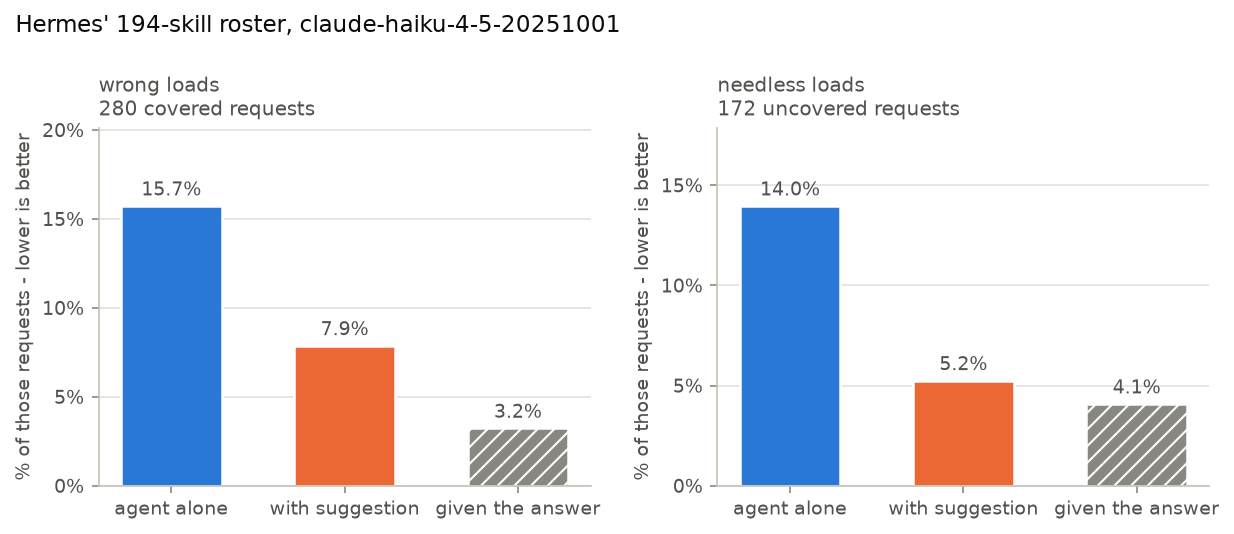

In [ ]:
CHART_PALETTES = {
    "light": {
        "surface": "#ffffff", "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781",
        "grid": "#e1e0d9", "axis": "#c3c2b7", "blue": "#2a78d6", "orange": "#eb6834",
    },
    "dark": {
        "surface": "#0d0a0f", "ink": "#fafafa", "ink2": "#d4d4d8", "muted": "#a1a1aa",
        "grid": "#2e2e33", "axis": "#52525b", "blue": "#5b9be8", "orange": "#f08050",
    },
}


def draw_loads(p: dict) -> plt.Figure:
    ARM_COLOR = {"baseline": p["blue"], "TypeSafe": p["orange"], "oracle": p["muted"]}
    ARM_LABEL = {  # display names only: the arm keys are part of each turn's cache key
        "baseline": "agent alone",
        "TypeSafe": "with suggestion",
        "oracle": "given the answer",
    }


    def style(ax):
        ax.set_facecolor(p["surface"])
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color(p["axis"])
        ax.tick_params(colors=p["muted"], labelcolor=p["ink2"], labelsize=9)
        ax.set_axisbelow(True)


    panels = [
        ("wrong_load", f"wrong loads\n{len(POSITIVES)} covered requests"),
        ("needless_load", f"needless loads\n{len(NEGATIVES)} uncovered requests"),
    ]
    names = list(scores)
    fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.6), facecolor=p["surface"])
    for ax, (metric, title) in zip(axes, panels):
        style(ax)
        ax.grid(axis="y", color=p["grid"], linewidth=0.8)
        values = [scores[arm][metric] for arm in names]
        bars = ax.bar(
            [ARM_LABEL[arm] for arm in names],
            values,
            0.58,
            color=[ARM_COLOR[arm] for arm in names],
            # the oracle is a ceiling, not a competitor: gray, and hatched so it never depends
            # on colour alone
            hatch=["", "", "///"],
            edgecolor=p["surface"],
            linewidth=1.2,
        )
        ax.bar_label(
            bars,
            labels=[f"{v:.1%}" for v in values],
            padding=3,
            color=p["ink2"],
            fontsize=9,
        )
        ax.set_title(title, loc="left", color=p["ink2"], fontsize=9.5)
        ax.set_ylim(0, max(values) * 1.28)
        ax.yaxis.set_major_locator(MultipleLocator(0.05))
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
        ax.set_ylabel("% of those requests - lower is better", color=p["ink2"], fontsize=9)
    fig.suptitle(
        f"Hermes' {len(ROSTER)}-skill roster, {AGENT_MODEL}",
        x=0.02,
        ha="left",
        color=p["ink"],
        fontsize=11,
    )
    fig.tight_layout()
    return fig


# The docs build sets COOKSAFE_RENDER and also draws a dark copy.
for theme in ("light", "dark") if os.environ.get("COOKSAFE_RENDER") else ("light",):
    fig = draw_loads(CHART_PALETTES[theme])
    display(fig, metadata={"theme": theme})
    plt.close(fig)

## What the results show

- Wrong loads fell from 15.7% to 7.9%, closing more than half the gap between guessing
  from a truncated index and being handed the answer. Needless loads fell from 14.0% to
  5.2%, closing nearly all of theirs.
- Some requests the agent had right on its own come back wrong once a suggestion is
  attached: of the 280 covered requests, the suggestion broke 7 and fixed 29.

## Open it in the playground

Build a playground link for the deck request from step 4, using each candidate's full
description and body excerpt as its criteria.

In [ ]:
demo_shortlist = tuple(name for name, _ in first_pass(DEMO[1])["ranked"][:SHORTLIST])
playground_link = make_playground_link(
    build_state(DEMO[1]),
    rerank_questions(demo_shortlist, EXCERPT_CHARS),
)
display(
    Markdown(
        f"🔗 [Open the shortlist + questions in the TypeSafe playground]({playground_link})"
    )
)

🔗 [Open the shortlist + questions in the TypeSafe playground](https://console.typesafe.ai/playground#share/N4IgJg9gxgrgtgUwHYBcAqCAeKQC4AEIwAOiAE4ICOMCAziqQaQJIDkAbgvgOYQr4BDfFAA2AS2T8ADmJRQAFvjAIoAa0G1B+AHRSpKTPhQI4UkQOP4AtPmb4kCBGCMQlMM2KgWutccvwALKya5gCeEDD8AGYQZEbyFFwOAO74UmQQYDBQ-L5iypoCSM4o8sj49GRiUvgR-EWh+DBIMLRO+IhgYgIA9BQihVHGZMkCZM60rqVcUWIiXGK0SKz8AEYiEN5g2qQANPikFFCSAPpQEKhYDHgHIKQAviD7IOkQpii0GNg3RKTJ8p55Ix8CQQChQlIEMDSAoIJ4oU9bmIkJVsigxBdaNCQABRTACHIiRoXLgQKLxOg+VRzAb4RYU-BVbjyfgklz4DYCZwxOLTJptMjBDneeiMqg0ejafAAdQBClqDgA-PgAEoILn4f4WfDq+UElAwAQiIlKCB0fZIPj4ABWrX4sk0SAEiB2iJhVWG3WBoL0BisAki8li2IAQjA5s4AAoQZIIMjR5H8ZRqTRlLnzWiaZKyRRSUKlC5WX2YKWAFAJ8ABiNL6TD+wOxfCRjJZY5aXQ1-CzeYKpSLdStZHcfAAAzzBaQRZrw6lAFU2pqykh8OEYPZHCVXMpxJw4kJk+oBIVO3MuGN0VF9RarWAqpwtNuuNHY-G4agKnRaBikFKAIJgAT6O0UQZHA+A-qgCQQDIUBCqONZ1gWZDDoIxQjjIcjyFY+7IbQ1LGpoyL4AA2kUpQZNBtA9LMTpIFA3QiFYArsPCtAALoABQsigUi0LgPQ9NwOYwKs2jnHAPSkZBFFUciRR0UajFxsxxy0AAlFKaBlPgACyADCkb4D0+AAPJRLMxxWAAUgAyvgqxkHJZSaGSDKxGIglOrSYxcDeUGQs45alPSh60PAdD4GmYAZpokb5kG374AAYg2fL2ZsyhkPsRoUFyoSMQCejtE+cYJm+AaIYOFR4SI+DsXkBT7LQkICKocb2Hw5o6nAqxOLQ+ydN0qmNY4DKrOGIgoFYhHDnAngZJMQxWGS5kIDh1UaQCmi4TSdJHuIzLDFYsbuSyaQWMMS4Gg43INnAmQIAxqwEq1zj7po7HofKb37MwukdCYEB9TqYxIIOjodWpC5xlwCA7o0LTdW1cB2kYDmtigrhCJMMBkK2ySxKoqwQBAqhShWey3LNUDzWSk3LfC2K6Tlxj7DlYBZahTiyDKsTs42MYla+KAc84eLHDVXZ0GWlY6XNgO0yZZnwvg1nVfgTPqizYpcvsXPCyhJQmGY3g8+MtXTpAUCYMOQ388+pX8Ox07FjbIv4GLD3m9omADNb+zTlAtDsDbx4ZrUZniA4mo5hUcBGjVsXjurAAyzCaGNcyskuY7xVh0CYPsOeFsWbtQcgeY+1KpkrXSHwPeS9IODua5OE4UrMEmZrg6ykJLvM3AEo0qyyWQjQ8nHHxe5bw7++2KAzyO3sDCHRSvV37X8BQxRtVIAjcOF2YFpE+DJ2I9kINX8Jk1WsrlBj+Bzo+njqHy48WPs0xLmzteaBQUTQ7RLgh9FDDm2saE4zEEDJGQj1HkQCCaDgIAAHySiefAKC1T-y3q2FBaAISeCNBoVQmgUEoKsOQ9B1gKFkOoZQi2+dkIoOHH-ABKkej43GNoOAYBGFiikLED4+x5goGGEDc4qA0aCJHMAYAGNWpIHuPcZCxhTDmGMEDFAaMXrCHkEUfeYi3iIFQCQuhc9rZ0JYdgugPR+HPn4YmLhPDKGfUUN9OyDlihWBUcbSwbiFBnjFMBBE+xSAATMAgKwlp1HYm0kUPeXAfx6G7AAOQhvgZiQhEB3RTswAg1NNYIGGmMBQusugoGllWRJ4T8CpPUQ-ecM0AbKNcHHJ0+8wJJK4LU8KXQjgoBNMBN4DJhizU8lKbpW1Qi0UENTQGhRjQdOqcoZS4UMl0l0hsGA2xKxVibNDagixZDhRsAAKhOXHKAxlrJnOjqUGpENtBhOsLYFEKB44EGHOfVIbyaikQuBiZsZAehZNcAAMlBe4qBdJXnxxQhjUGsRMhApBcCppzyADiHj+A-kiG8CwX4ZkqU0PfCZjy9BQ2ziBQCzh2LWVCPQEwKsEAiLBvgQASYSNlvIPdlYFcUTy-KpHZMpFzskfs8x+u5cLEtcPk7w+xIHJH2A2NoxTFBVJSWkmw1kBDMSQEOZEb90QXHZKSp5PJhDzVoFhWGysCREuecZMgA9QYAC9KpRPComVwMQRAZU0DYPE-CyDoj1RvcK99YlkFUJAZISAegAAk0DaWTkK2+S5knGTQKK+cNhjKrE-F0Io6SAwTQ6HE-eRj+ActaFwPkw4ID5vyN0JAa0do2BDOqOIEyeVtF3g5SwTz2JRIqO4INxhnBlAoIKmwABFcMahBD71QEtJAJoPWaGrfOOtILR7NIgCIB49wQkgFmB8XAuBiwISDGQb0pBwSQmxJaGAB63QgGRKiHIX4sQ3FIAAEXXnyMBNVWCXvKte1gpoGRNRUGIcy8RKp8hrYKX+4o6D1ClZ2WIyoO67SUHQamZ92iHgIGGCMdtBaJjwymCK6oooflubmOKxcayuiPbcU9vFcBUxpotemxxb1gghAiJgIAn0vuPe+zRaIv3Yn-eGrSQH8CsG4-LXjStjgQcgFByEdE4NBVDYhgUQoKDUDQ0QzQPJsP2k0AUAjPVnDEfVszQp2s+arx1GU02fNiovkTG7D2EsTy0FY8ejj56wnzEiRDAT97hO3DExTUgkmyDScxLJgDCm1asAixE9dmmpgKZ07Bzw8GDNaSQ8Z1DopDzEMw2QKzuHbNVHsxoAgsS2kJM6fcupayQU5Lyc5opuN5ClNkKxx4zwAJiAAGpxk-BcH47AACMIB7hAA)

## What's next

The same shape shows up elsewhere:
[Routing by probability](https://console.typesafe.ai/docs/patterns/probability-routing)
for routing to a handler rather than a skill,
[Confidence](https://console.typesafe.ai/docs/confidence) for picking the two
thresholds, and
[Speculative fan-out](https://console.typesafe.ai/docs/patterns/fan-out) for putting every
question in one request.